In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="Set2")

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

# Read the CSV dataset
df = pd.read_csv(
    "/kaggle/input/datasets/dranilgavade/eda-student-perfomace-abg-exp1/eda_student_performance_500.csv"
)

# Display confirmation
print("Dataset loaded successfully!")

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display first 5 rows
print("\nFirst 5 Rows:")
display(df.head(5))

# Display last 5 rows
print("\nLast 5 Rows:")
display(df.tail(5))

Dataset loaded successfully!
Dataset Shape: (500, 7)

First 5 Rows:


,Study_Hours,Attendance_Percent,Sleep_Hours,Assignment_Score,Class_Participation,Department,Exam_Score
0,2.7,68.4,6.8,65.8,8.6,ME,44.7
1,5.1,67.7,6.5,97.6,7.3,CSE,86.2
2,3.9,64.3,7.7,70.2,6.0,Civil,67.6
3,3.4,83.1,6.7,80.2,5.1,ME,52.9
4,3.6,93.3,6.6,76.2,5.1,ECE,66.9



Last 5 Rows:


,Study_Hours,Attendance_Percent,Sleep_Hours,Assignment_Score,Class_Participation,Department,Exam_Score
495,2.6,79.3,6.7,61.4,6.6,CSE,63.9
496,4.5,79.6,5.7,66.0,4.5,CSE,62.1
497,5.2,74.7,6.2,83.3,6.1,ME,69.5
498,3.9,86.9,6.1,90.0,2.8,CSE,62.3
499,1.9,84.4,6.5,84.3,8.8,CSE,58.0


In [3]:
# Missing values
print("Missing Values:")
print(df.isnull().sum())

# Missing value percentage
print("\nMissing Value Percentage:")
print((df.isnull().mean() * 100).round(2))

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
Study_Hours            0
Attendance_Percent     0
Sleep_Hours            8
Assignment_Score       6
Class_Participation    0
Department             4
Exam_Score             0
dtype: int64

Missing Value Percentage:
Study_Hours            0.0
Attendance_Percent     0.0
Sleep_Hours            1.6
Assignment_Score       1.2
Class_Participation    0.0
Department             0.8
Exam_Score             0.0
dtype: float64

Duplicate Records: 0


In [4]:
print("Descriptive Statistics:")
display(df.describe().round(2))

# Additional statistical measures
print("\nMean:")
display(df.mean(numeric_only=True))

print("\nMedian:")
display(df.median(numeric_only=True))

print("\nStandard Deviation:")
display(df.std(numeric_only=True))

print("\nSkewness:")
display(df.skew(numeric_only=True))

Descriptive Statistics:


,Study_Hours,Attendance_Percent,Sleep_Hours,Assignment_Score,Class_Participation,Exam_Score
count,500.00,500.00,492.00,494.00,500.00,500.00
mean,3.87,79.96,6.89,75.86,6.10,67.09
std,1.53,10.25,1.02,10.28,1.98,11.75
min,0.30,35.00,3.80,40.10,0.30,24.80
25%,2.90,73.20,6.20,68.90,4.70,59.60
50%,3.90,80.45,6.90,75.70,6.10,66.40
75%,4.80,87.10,7.50,83.18,7.60,75.25
max,12.00,100.00,9.80,100.00,10.00,100.00



Mean:


Study_Hours             3.872600
Attendance_Percent     79.958000
Sleep_Hours             6.889431
Assignment_Score       75.857287
Class_Participation     6.099800
Exam_Score             67.094400
dtype: float64


Median:


Study_Hours             3.90
Attendance_Percent     80.45
Sleep_Hours             6.90
Assignment_Score       75.70
Class_Participation     6.10
Exam_Score             66.40
dtype: float64


Standard Deviation:


Study_Hours             1.528785
Attendance_Percent     10.248537
Sleep_Hours             1.015426
Assignment_Score       10.282576
Class_Participation     1.979074
Exam_Score             11.747214
dtype: float64


Skewness:


Study_Hours            0.442672
Attendance_Percent    -0.395726
Sleep_Hours            0.011834
Assignment_Score      -0.068251
Class_Participation   -0.171526
Exam_Score             0.058370
dtype: float64

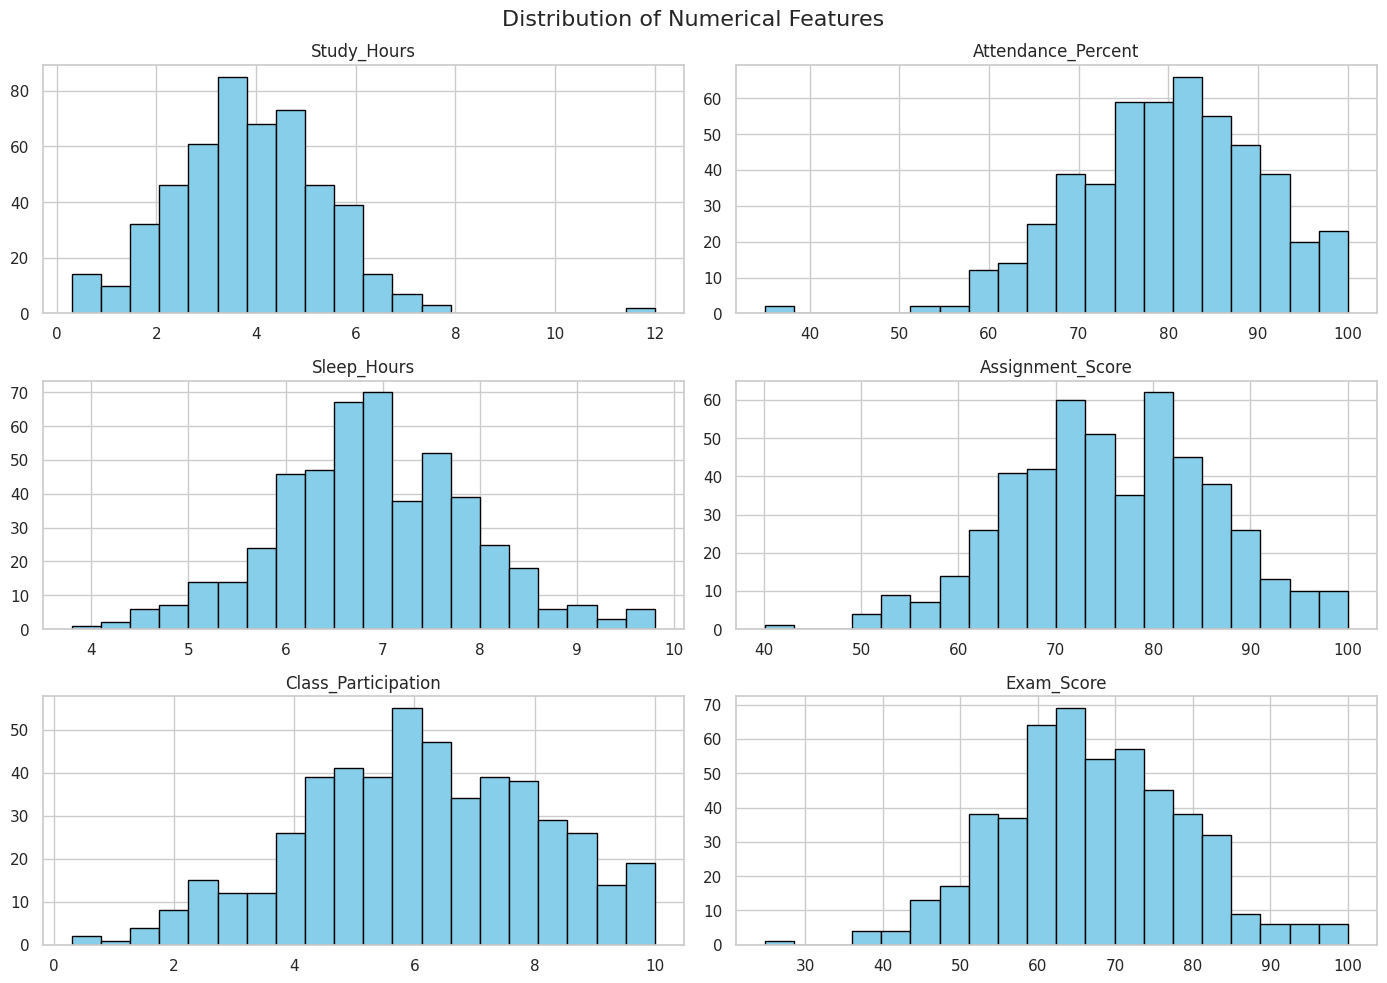

In [5]:
numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].hist(
    bins=20,
    figsize=(14, 10),
    edgecolor='black',
    color='skyblue'
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

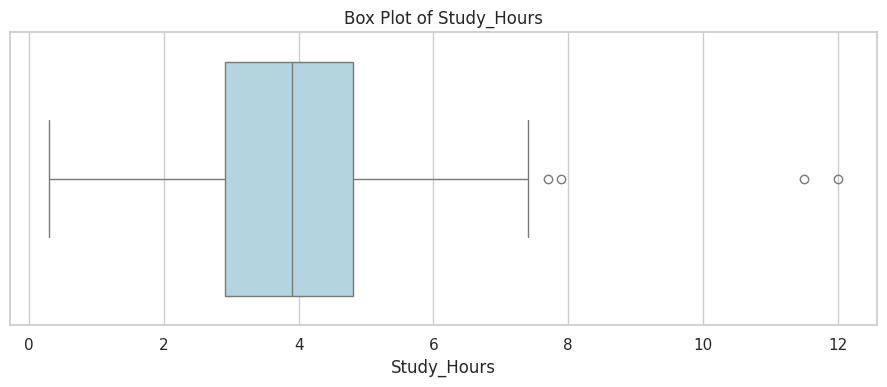

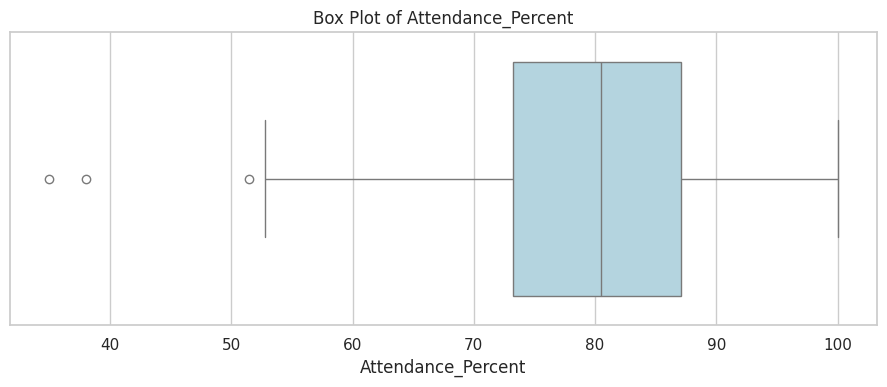

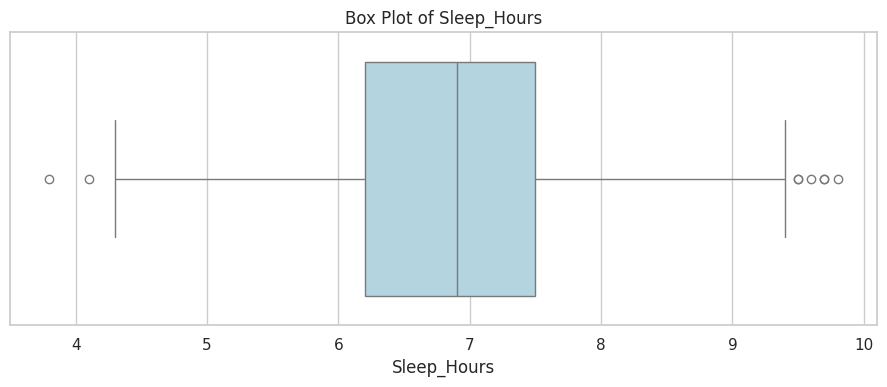

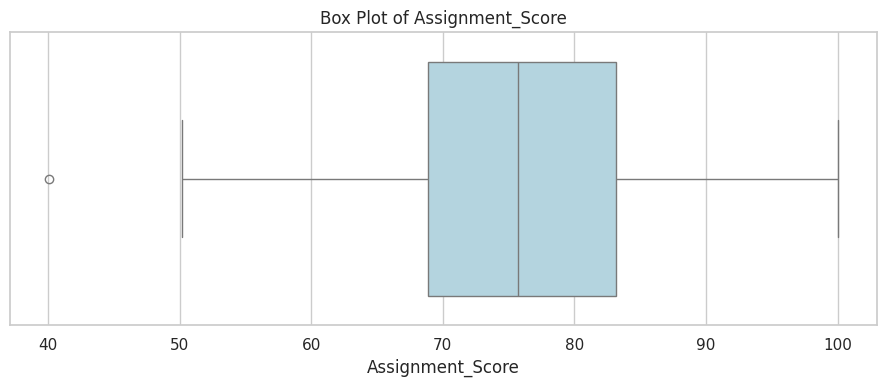

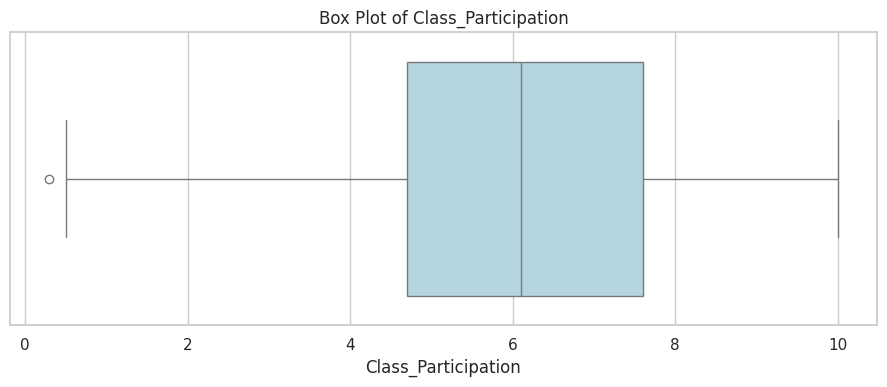

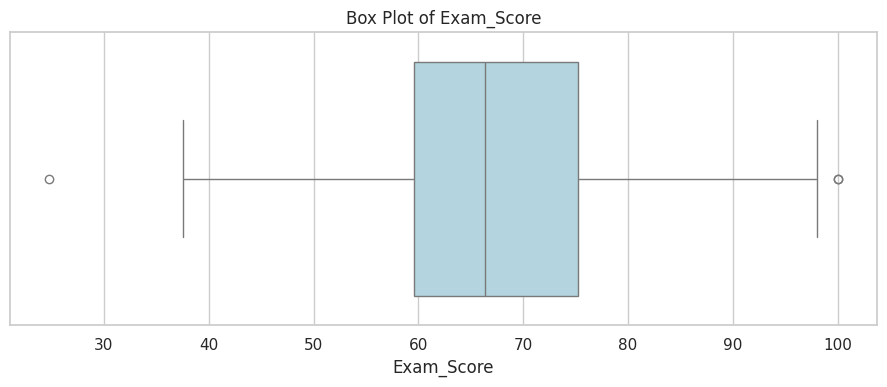

In [6]:
for col in numeric_cols:

    plt.figure(figsize=(9, 4))

    sns.boxplot(x=df[col], color='lightblue')

    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

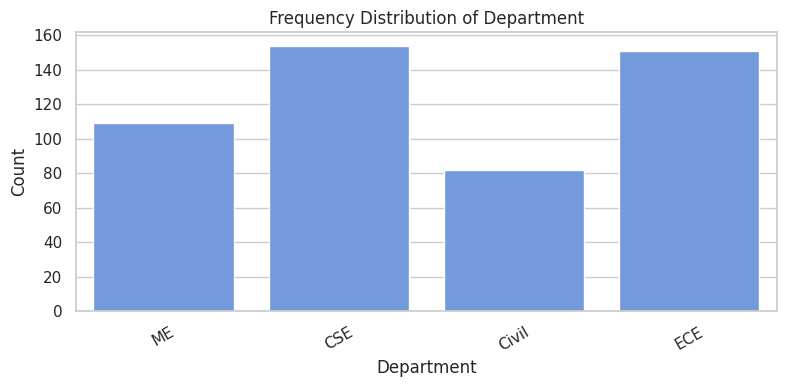

In [7]:
categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_cols:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=col,
        color='cornflowerblue'
    )

    plt.title(f"Frequency Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

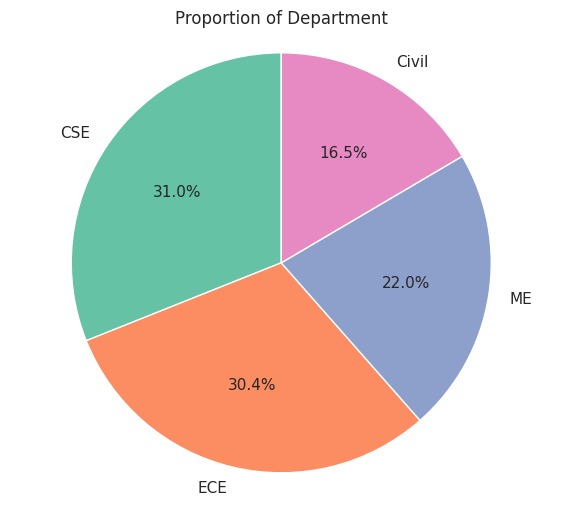

In [8]:
for col in categorical_cols:

    counts = df[col].value_counts()

    if len(counts) <= 5:

        plt.figure(figsize=(7, 6))

        plt.pie(
            counts,
            labels=counts.index,
            autopct='%1.1f%%',
            startangle=90
        )

        plt.title(f"Proportion of {col}")
        plt.axis('equal')
        plt.show()

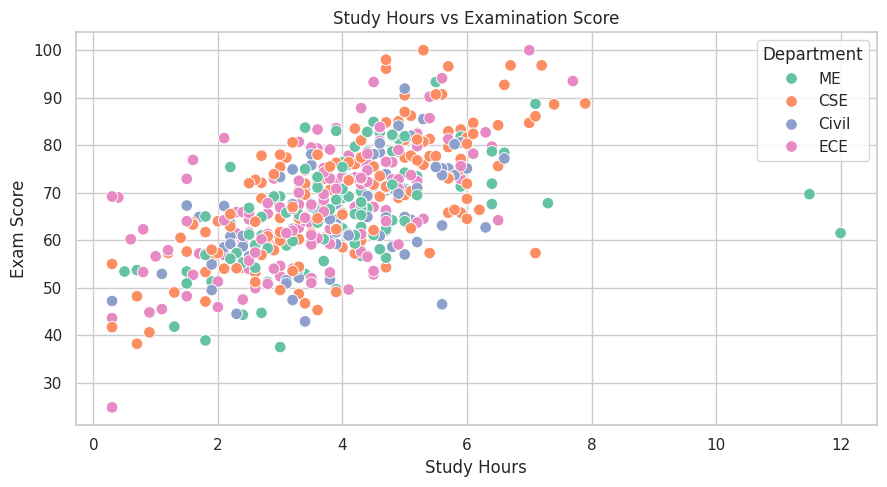

In [9]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Study_Hours',
    y='Exam_Score',
    hue='Department',
    s=70
)

plt.title("Study Hours vs Examination Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.tight_layout()
plt.show()

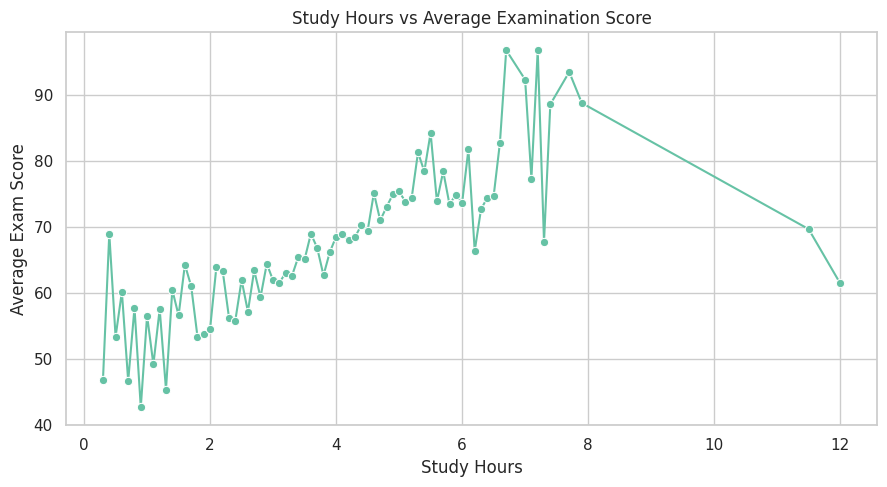

In [10]:
study_trend = (
    df.groupby('Study_Hours')['Exam_Score']
    .mean()
    .reset_index()
    .sort_values('Study_Hours')
)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=study_trend,
    x='Study_Hours',
    y='Exam_Score',
    marker='o'
)

plt.title("Study Hours vs Average Examination Score")
plt.xlabel("Study Hours")
plt.ylabel("Average Exam Score")

plt.tight_layout()
plt.show()

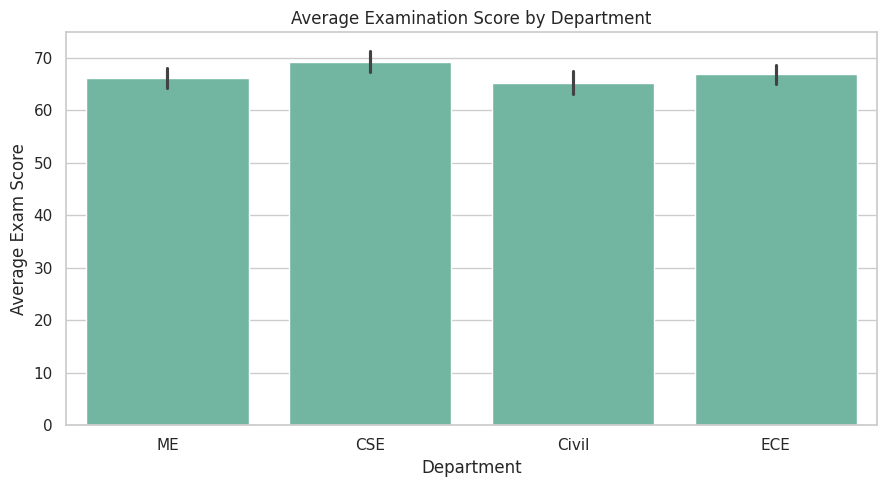

In [11]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='Department',
    y='Exam_Score',
    errorbar=('ci', 95)
)

plt.title("Average Examination Score by Department")
plt.xlabel("Department")
plt.ylabel("Average Exam Score")

plt.tight_layout()
plt.show()

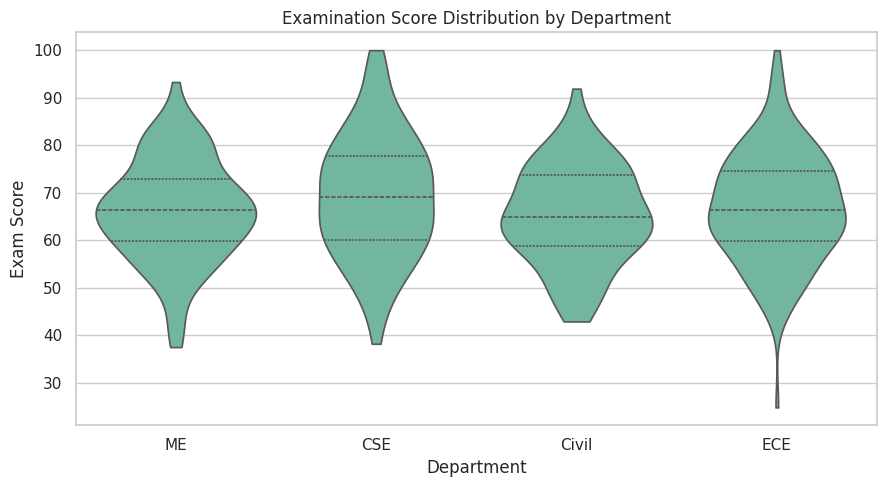

In [12]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x='Department',
    y='Exam_Score',
    inner='quartile',
    cut=0
)

plt.title("Examination Score Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Exam Score")

plt.tight_layout()
plt.show()

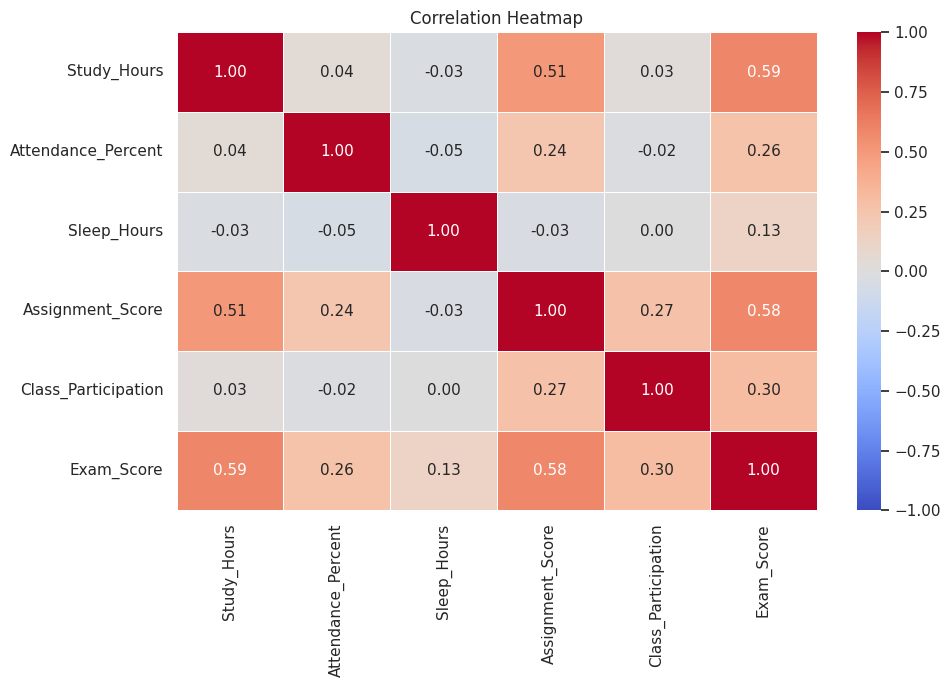

In [13]:
correlation = df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

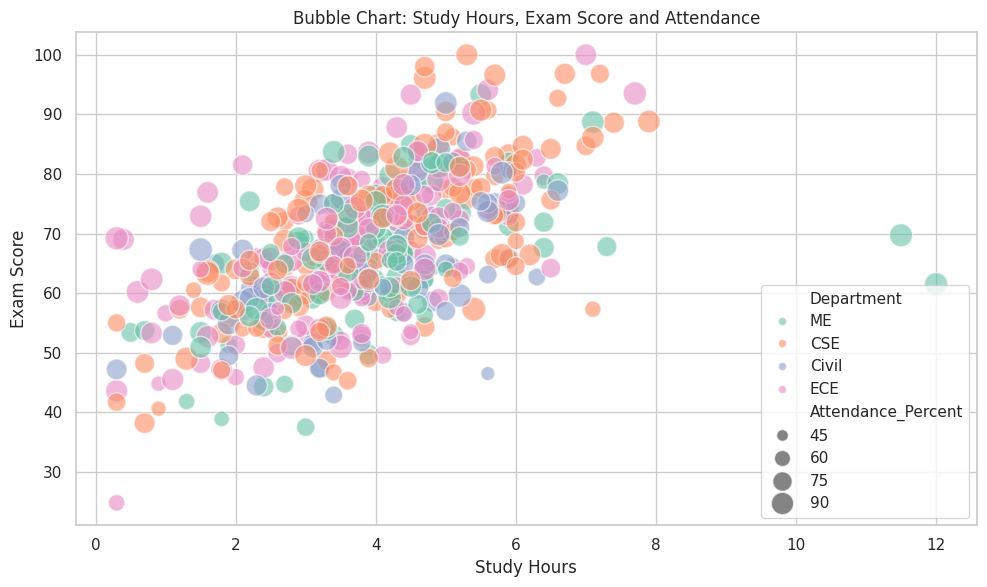

In [14]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Study_Hours',
    y='Exam_Score',
    size='Attendance_Percent',
    hue='Department',
    sizes=(30, 300),
    alpha=0.6
)

plt.title("Bubble Chart: Study Hours, Exam Score and Attendance")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.tight_layout()
plt.show()

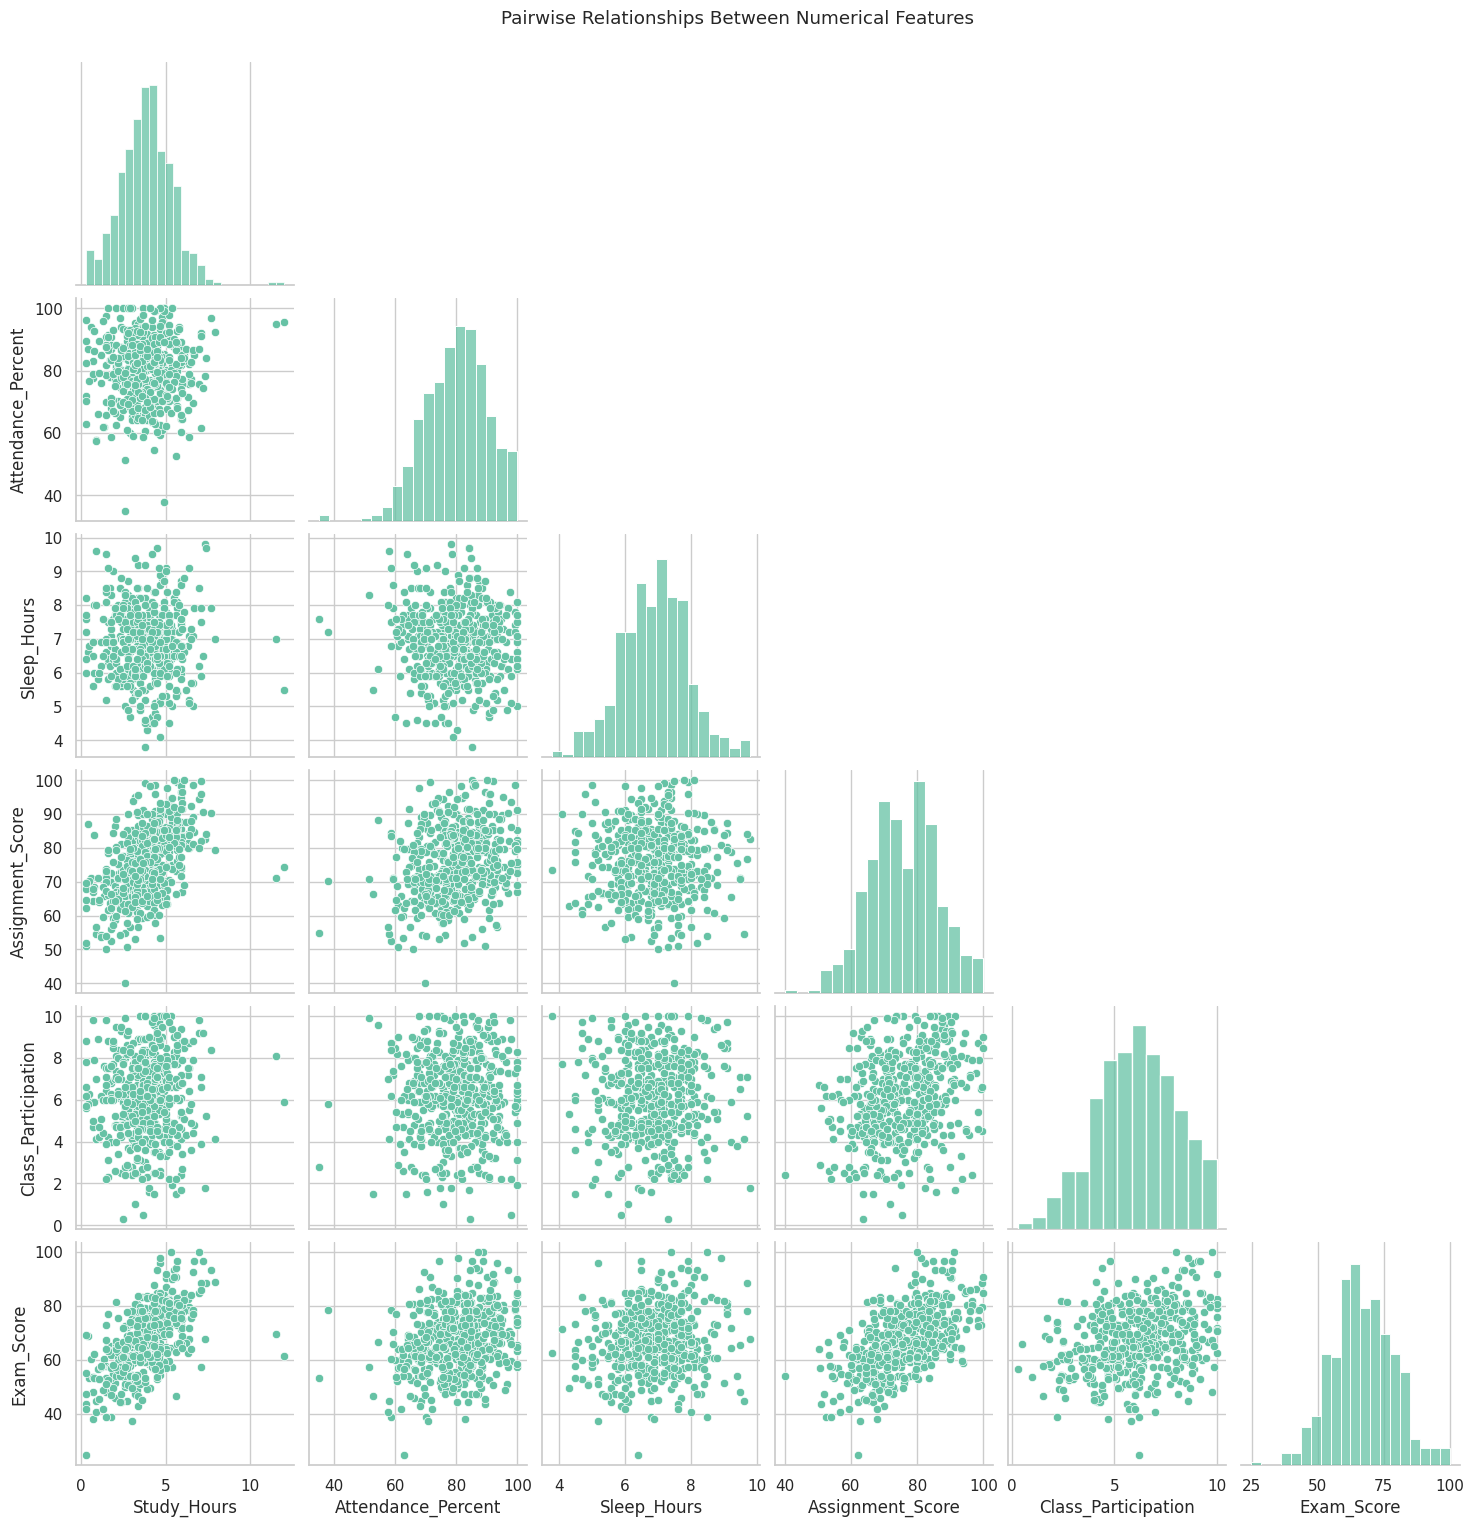

In [18]:
sns.pairplot(
    df.select_dtypes(include=np.number),
    corner=True,
    diag_kind='hist'
)

plt.suptitle("Pairwise Relationships Between Numerical Features", y=1.02)
plt.show()

In [19]:
for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print("\nFeature:", col)
    print("Lower Bound:", round(lower, 2))
    print("Upper Bound:", round(upper, 2))
    print("Potential Outliers:", len(outliers))


Feature: Study_Hours
Lower Bound: 0.05
Upper Bound: 7.65
Potential Outliers: 4

Feature: Attendance_Percent
Lower Bound: 52.35
Upper Bound: 107.95
Potential Outliers: 3

Feature: Sleep_Hours
Lower Bound: 4.25
Upper Bound: 9.45
Potential Outliers: 8

Feature: Assignment_Score
Lower Bound: 47.49
Upper Bound: 104.59
Potential Outliers: 1

Feature: Class_Participation
Lower Bound: 0.35
Upper Bound: 11.95
Potential Outliers: 1

Feature: Exam_Score
Lower Bound: 36.12
Upper Bound: 98.72
Potential Outliers: 3


In [20]:
correlation = df.select_dtypes(
    include=np.number
).corr()

if 'Exam_Score' in correlation.columns:

    score_corr = correlation['Exam_Score'].drop(
        'Exam_Score'
    ).sort_values(ascending=False)

    print("Correlation with Examination Score:")
    display(score_corr.to_frame("Correlation"))

Correlation with Examination Score:


,Correlation
Study_Hours,0.586037
Assignment_Score,0.579682
Class_Participation,0.302915
Attendance_Percent,0.264633
Sleep_Hours,0.131784


In [21]:
print("=" * 50)
print("EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 50)

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nNumerical Features:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Features:")
print(df.select_dtypes(include=['object', 'category']).columns.tolist())

print("\nExamination Score Statistics:")
if 'Exam_Score' in df.columns:
    print(df['Exam_Score'].describe())

print("\nEDA Completed Successfully!")

EXPLORATORY DATA ANALYSIS SUMMARY
Dataset Shape: (500, 7)

Missing Values:
18

Duplicate Records:
0

Numerical Features:
['Study_Hours', 'Attendance_Percent', 'Sleep_Hours', 'Assignment_Score', 'Class_Participation', 'Exam_Score']

Categorical Features:
['Department']

Examination Score Statistics:
count    500.000000
mean      67.094400
std       11.747214
min       24.800000
25%       59.600000
50%       66.400000
75%       75.250000
max      100.000000
Name: Exam_Score, dtype: float64

EDA Completed Successfully!
